# Clasificador de ladridos según el tamaño del animal. - Base de datos

### Pruebas estadisticas

In [209]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import librosa
from scipy import stats

df = pd.read_csv(f'metadataDogsSpeakTDS.csv')

TAMANO_RAZA = {
    'chihuahua':       'pequeño',
    'shiba inu':       'pequeño',
    'pitbull':         'grande',
    'husky':           'grande',
    'german shepherd': 'grande',
}

df['size'] = df['breed'].map(TAMANO_RAZA)
print(df['size'].isna().sum(), 'audios sin tamaño')

perros = df.drop_duplicates('dog_id')[['dog_id', 'breed', 'sex', 'size']]

print(len(perros), 'perros')
print(perros['breed'].value_counts())
print(df.groupby('dog_id').size().value_counts().sort_index())   # cuántos perros tienen 1, 2, 3... audios

0 audios sin tamaño
122 perros
breed
german shepherd    31
husky              28
pitbull            27
shiba inu          24
chihuahua          12
Name: count, dtype: int64
2    110
4     12
Name: count, dtype: int64


In [210]:
import os
import glob
import wave

ALPHA = 0.05

def evaluar_hipotesis(nombre, h0, h1, estadistico_txt, p_valor, decision_si_rechaza, decision_no_rechaza):
    print(f"\n{'='*70}")
    print(f"PRUEBA: {nombre}")
    print(f"  H0: {h0}")
    print(f"  H1: {h1}")
    print(f"  Nivel de significancia: alpha = {ALPHA}")
    print(f"  Resultado: {estadistico_txt}, p-valor = {p_valor:.6f}")
    if p_valor < ALPHA:
        print(f"  Decisión estadística: Como p ({p_valor:.6f}) < alpha ({ALPHA}), SE RECHAZA H0.")
        print(f"  Decisión metodológica: {decision_si_rechaza}")
    else:
        print(f"  Decisión estadística: Como p ({p_valor:.6f}) >= alpha ({ALPHA}), NO SE RECHAZA H0.")
        print(f"  Decisión metodológica: {decision_no_rechaza}")

# RAZA A SEXO
tabla_rs = pd.crosstab(perros['breed'], perros['sex'])
chi2_rs, p_rs, gl_rs, _ = stats.chi2_contingency(tabla_rs)
evaluar_hipotesis(
    nombre="Independencia entre Raza y Sexo (Chi-cuadrado)",
    h0="La raza y el sexo de los perros son independientes.",
    h1="Existe dependencia entre la raza y el sexo de los perros.",
    estadistico_txt=f"Chi2 = {chi2_rs:.4f} (gl = {gl_rs})",
    p_valor=p_rs,
    decision_si_rechaza="Verificar si esta dependencia de sexo se mantiene al agrupar por tamaño (Prueba 2).",
    decision_no_rechaza="El sexo se distribuye homogéneamente entre todas las razas."
)

# TAMAÑO A SEXO
tabla_ts = pd.crosstab(perros['size'], perros['sex'])
chi2_ts, p_ts, gl_ts, _ = stats.chi2_contingency(tabla_ts)
evaluar_hipotesis(
    nombre="Independencia entre Tamaño y Sexo (Chi-cuadrado)",
    h0="El tamaño del perro (grande/pequeño) y su sexo son independientes.",
    h1="Existe dependencia entre el tamaño del perro y su sexo.",
    estadistico_txt=f"Chi2 = {chi2_ts:.4f} (gl = {gl_ts})",
    p_valor=p_ts,
    decision_si_rechaza="Controlar el efecto del sexo al construir los vectores prototipo.",
    decision_no_rechaza="El sexo no es variable de confusión para clasificar por tamaño; no requiere separación por sexo."
)

# BALANCE DE PERROS POR TAMAÑO
conteo_tam = perros['size'].value_counts()
chi2_bal, p_bal = stats.chisquare(conteo_tam)
evaluar_hipotesis(
    nombre="Balance de individuos por Tamaño (Chi-cuadrado de bondad de ajuste)",
    h0="Hay igual proporción de perros grandes y pequeños (50% y 50%).",
    h1="Existe desbalance en la proporción de perros grandes y pequeños.",
    estadistico_txt=f"Chi2 = {chi2_bal:.4f} (gl = 1)",
    p_valor=p_bal,
    decision_si_rechaza="Calcular prototipos promediando primero por perro y luego por raza (sin mezclar todos los audios directos).",
    decision_no_rechaza="Se pueden promediar directamente todos los audios de cada clase."
)

# DURACIÓN DE LADRIDOS (GRANDES VS. PEQUEÑOS)
archivos_wav = glob.glob('DogSpeak_Seleccion/**/*.wav', recursive=True)
mapa_rutas = {os.path.basename(ruta): ruta for ruta in archivos_wav}

duraciones, fs_list = [], []
for fname in df['filename']:
    with wave.open(mapa_rutas[fname], 'rb') as wf:
        fs = wf.getframerate()
        fs_list.append(fs)
        duraciones.append(wf.getnframes() / float(fs))

df['fs'] = fs_list
df['duracion_s'] = duraciones

print(f"\nFrecuencias de muestreo encontradas (Hz): {df['fs'].value_counts().to_dict()}")
print(df.groupby('size')['duracion_s'].describe().round(4))

dur_g = df[df['size'] == 'grande']['duracion_s']
dur_p = df[df['size'] == 'pequeño']['duracion_s']

# Paso previo: Normalidad (Shapiro-Wilk)
_, p_norm_g = stats.shapiro(dur_g)
_, p_norm_p = stats.shapiro(dur_p)
print(f"\nNormalidad (Shapiro-Wilk): p_grande = {p_norm_g:.4e}, p_pequeño = {p_norm_p:.4e}")

if p_norm_g >= ALPHA and p_norm_p >= ALPHA:
    stat_dur, p_dur = stats.ttest_ind(dur_g, dur_p)
    metodo = f"t-Student = {stat_dur:.4f}"
else:
    stat_dur, p_dur = stats.mannwhitneyu(dur_g, dur_p)
    metodo = f"Mann-Whitney U = {stat_dur:.1f}"

evaluar_hipotesis(
    nombre="Comparación de duración de ladridos entre Grandes y Pequeños",
    h0="La duración de los ladridos es igual en perros grandes y pequeños.",
    h1="La duración de los ladridos difiere entre perros grandes y pequeños.",
    estadistico_txt=metodo,
    p_valor=p_dur,
    decision_si_rechaza="La duración aporta información discriminativa; elegir ventana corta según el percentil mínimo.",
    decision_no_rechaza="La duración no discrimina tamaño; enfocar las características en el contenido espectral (bancos de filtros)."
)


PRUEBA: Independencia entre Raza y Sexo (Chi-cuadrado)
  H0: La raza y el sexo de los perros son independientes.
  H1: Existe dependencia entre la raza y el sexo de los perros.
  Nivel de significancia: alpha = 0.05
  Resultado: Chi2 = 20.6581 (gl = 4), p-valor = 0.000370
  Decisión estadística: Como p (0.000370) < alpha (0.05), SE RECHAZA H0.
  Decisión metodológica: Verificar si esta dependencia de sexo se mantiene al agrupar por tamaño (Prueba 2).

PRUEBA: Independencia entre Tamaño y Sexo (Chi-cuadrado)
  H0: El tamaño del perro (grande/pequeño) y su sexo son independientes.
  H1: Existe dependencia entre el tamaño del perro y su sexo.
  Nivel de significancia: alpha = 0.05
  Resultado: Chi2 = 0.0000 (gl = 1), p-valor = 1.000000
  Decisión estadística: Como p (1.000000) >= alpha (0.05), NO SE RECHAZA H0.
  Decisión metodológica: El sexo no es variable de confusión para clasificar por tamaño; no requiere separación por sexo.

PRUEBA: Balance de individuos por Tamaño (Chi-cuadrado d

### Extracción de caracteristicas

In [ ]:
from scipy.fft import dct

FS_OBJETIVO = 16000
WIN_LEN = int(FS_OBJETIVO * 0.025)   # 25 ms -> 400 muestras
HOP_LEN = int(WIN_LEN * 0.50)        # 50% solape -> 200 muestras

def extraer_mfcc_audio(ruta_audio):
    # Preprocesamiento: cargar mono, remuestrear a 16 kHz y normalizar amplitud
    y, _ = librosa.load(ruta_audio, sr=FS_OBJETIVO, mono=True)
    if np.max(np.abs(y)) > 0:
        y = y / np.max(np.abs(y))

    # Window + DFT (potencia) + Banco de filtros Mel (librosa)
    mel_potencia = librosa.feature.melspectrogram(
        y=y,
        sr=FS_OBJETIVO,
        n_fft=512,
        win_length=WIN_LEN,
        hop_length=HOP_LEN,
        window='hamming',
        n_mels=40,
        fmin=50.0,
        fmax=8000.0,
        power=2.0
    )

    # Conversión a dB y DCT -> 20 coeficientes MFCC
    mel_db = librosa.power_to_db(mel_potencia, ref=np.max) # POWER TO DB = potencia a escala de decibeles
    mfccs = dct(mel_db, type=2, axis=0, norm='ortho')[:20, :] # Conversión de la representación Mel a MFCC mediante DCT (Discrete Cosine Transform)

    # Resumen temporal: media y desviación estándar de cada coeficiente
    return np.concatenate([np.mean(mfccs, axis=1), np.std(mfccs, axis=1)])

# Extraer matriz de características de DogsSpeakTDS (268 audios x 40 características)
X_tds = np.array([extraer_mfcc_audio(mapa_rutas[fname]) for fname in df['filename']])
print("Shape de X_tds:", X_tds.shape)

Shape de X_tds: (268, 40)


# Análisis de similitud

### Vector de representación promedio

Vector de ambas categorias basada desde la DCT y los coeficientes cepstrales.

(40,) (38,)


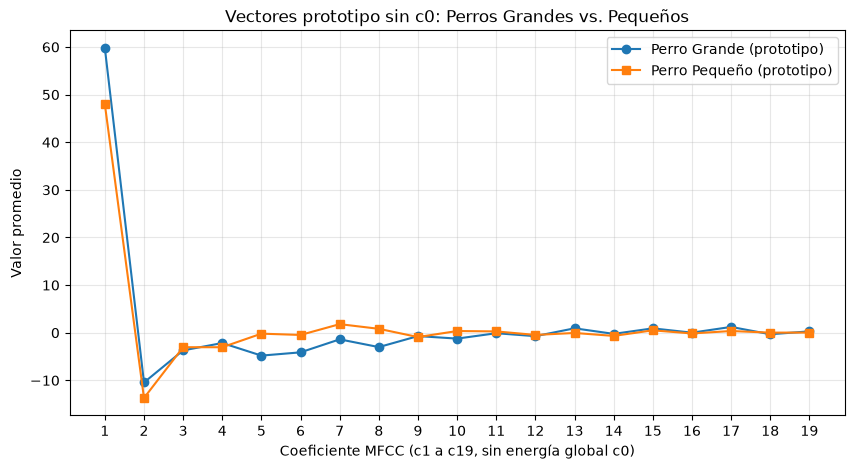

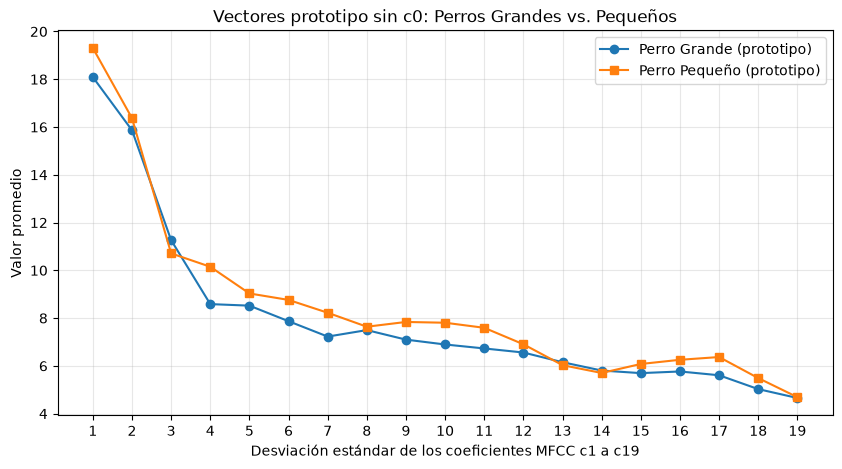

Nueva distancia coseno media (Grandes) : 0.1440
Nueva distancia coseno media (Pequeños): 0.1645


In [212]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cosine

# Índices de características SIN c0 (quita la media de c0 -> 0 y su desviación -> 20)
idx_sin_c0 = [i for i in range(40) if i not in (0, 20)]

# Prototipos: promedio de los vectores
Xdf = pd.DataFrame(X_tds)
Xdf['dog_id'] = df['dog_id'].values
Xdf['size'] = df['size'].values

por_perro_tds = Xdf.groupby(['size', 'dog_id']).mean()          # un vector por perro
vector_promedio_tamano = {t: por_perro_tds.loc[t].values.mean(axis=0)
                          for t in ['grande', 'pequeño']}

proto_grande  = vector_promedio_tamano['grande'][idx_sin_c0]
proto_pequeno = vector_promedio_tamano['pequeño'][idx_sin_c0]

print(vector_promedio_tamano['grande'].shape, proto_grande.shape)   # (40,) (38,)
# Gráfica haciendo zoom en los coeficientes MFCC 1 al 19 (sin c0)
plt.figure(figsize=(10, 5))
plt.plot(range(1, 20), vector_promedio_tamano['grande'][1:20], marker='o', label='Perro Grande (prototipo)')
plt.plot(range(1, 20), vector_promedio_tamano['pequeño'][1:20], marker='s', label='Perro Pequeño (prototipo)')

plt.xlabel("Coeficiente MFCC (c1 a c19, sin energía global c0)")
plt.ylabel("Valor promedio")
plt.title("Vectores prototipo sin c0: Perros Grandes vs. Pequeños")
plt.xticks(range(1, 20))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# Gráfica haciendo zoom en los coeficientes MFCC 19 al 38 (sin c0)
plt.figure(figsize=(10, 5))
plt.plot(range(1, 20), vector_promedio_tamano['grande'][21:40], marker='o', label='Perro Grande (prototipo)')
plt.plot(range(1, 20), vector_promedio_tamano['pequeño'][21:40], marker='s', label='Perro Pequeño (prototipo)')
plt.xlabel("Desviación estándar de los coeficientes MFCC c1 a c19")
plt.ylabel("Valor promedio")
plt.title("Vectores prototipo sin c0: Perros Grandes vs. Pequeños")
plt.xticks(range(1, 20))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# Al calcular distancia coseno, comparas usando idx_sin_c0
vec_g_sin_c0 = vector_promedio_tamano['grande'][idx_sin_c0]
vec_p_sin_c0 = vector_promedio_tamano['pequeño'][idx_sin_c0]

dist_g_nueva = np.array([cosine(x[idx_sin_c0], vec_g_sin_c0) for x in X_tds[df['size'] == 'grande']])
dist_p_nueva = np.array([cosine(x[idx_sin_c0], vec_p_sin_c0) for x in X_tds[df['size'] == 'pequeño']])

print(f"Nueva distancia coseno media (Grandes) : {dist_g_nueva.mean():.4f}")
print(f"Nueva distancia coseno media (Pequeños): {dist_p_nueva.mean():.4f}")

### Pruebas estadisticas mostrando las concentraciones y mostrando a su vez que tan concentradas se encuentran las representaciones de cada categoría alrededor de su respectivo vector de referencia.

=== CONCENTRACIÓN ALREDEDOR DEL PROTOTIPO (DISTANCIA COSENO SIN c0) ===
Grande  (n=172) -> Media: 0.1440 | Std: 0.1338 | Mediana: 0.0898 | IQR: 0.1223
Pequeño (n= 96) -> Media: 0.1645 | Std: 0.1090 | Mediana: 0.1331 | IQR: 0.1138


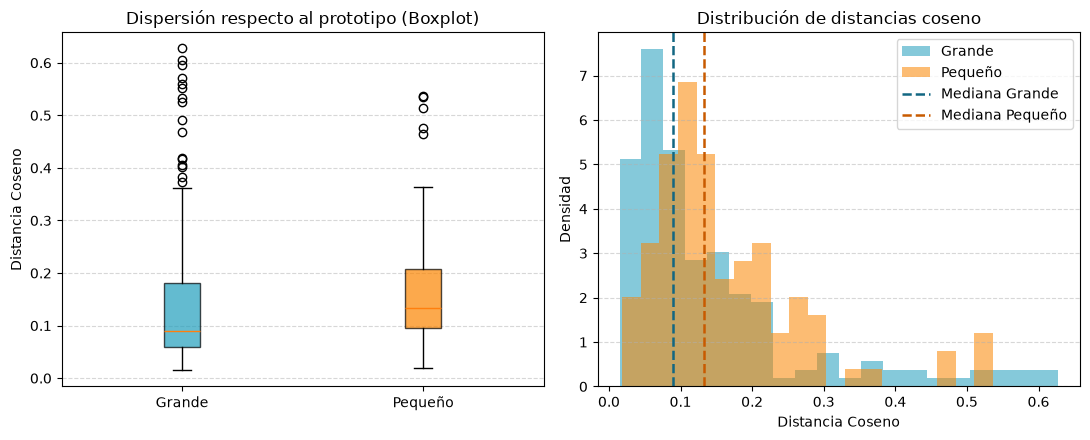


Normalidad (Shapiro-Wilk): p_grande = 1.4118e-15, p_pequeño = 1.9752e-08

PRUEBA: Comparación de concentración alrededor del prototipo (Grandes vs. Pequeños)
  H0: La concentración (distancia coseno al prototipo) es igual en grandes y pequeños.
  H1: Existe diferencia en la concentración entre perros grandes y pequeños.
  Nivel de significancia: alpha = 0.05
  Resultado: Mann-Whitney U = 6299.0, p-valor = 0.001301
  Decisión estadística: Como p (0.001301) < alpha (0.05), SE RECHAZA H0.
  Interpretación: Hay diferencia en la concentración. El grupo más concentrado (menor mediana de distancia) es: Grande.

PRUEBA: Chi-cuadrado de independencia (tamaño vs. cercanía al prototipo)
  H0: La proporción de audios cercanos al prototipo es igual en grandes y pequeños.
  H1: La proporción de audios cercanos al prototipo es distinta.
  Umbral de cercanía (mediana global de distancias): 0.1107
         Cerca  Lejos
Grande      99     73
Pequeño     35     61
Grande     0.576
Pequeño    0.365
  chi

In [213]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.spatial.distance import cosine

ALPHA = 0.05

# 1. Índices de la DCT sin c0 (quitamos el índice 0 de medias y el 20 de desviaciones estándar)
idx_sin_c0 = [i for i in range(40) if i not in (0, 20)]

# 2. Prototipos de referencia de cada categoría (38 características)
proto_grande  = vector_promedio_tamano['grande'][idx_sin_c0]
proto_pequeno = vector_promedio_tamano['pequeño'][idx_sin_c0]

# Separar audios de DogsSpeakTDS por tamaño y calcular distancia coseno a su prototipo
X_grande  = X_tds[df['size'] == 'grande'][:, idx_sin_c0]
X_pequeno = X_tds[df['size'] == 'pequeño'][:, idx_sin_c0]

dist_grande  = np.array([cosine(x, proto_grande) for x in X_grande])
dist_pequeno = np.array([cosine(x, proto_pequeno) for x in X_pequeno])

# 3. Resumen estadístico descriptivo
print("=== CONCENTRACIÓN ALREDEDOR DEL PROTOTIPO (DISTANCIA COSENO SIN c0) ===")
for nombre, d in [('Grande ', dist_grande), ('Pequeño', dist_pequeno)]:
    iqr = np.percentile(d, 75) - np.percentile(d, 25)
    print(f"{nombre} (n={len(d):3d}) -> Media: {d.mean():.4f} | Std: {d.std():.4f} | "
          f"Mediana: {np.median(d):.4f} | IQR: {iqr:.4f}")

# 4. Gráficos comparativos de distribución (Boxplot + Histograma de densidad)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

bp = axes[0].boxplot([dist_grande, dist_pequeno],
                     tick_labels=['Grande', 'Pequeño'], patch_artist=True)
for patch, color in zip(bp['boxes'], ['#219EBC', '#FB8500']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[0].set_title('Dispersión respecto al prototipo (Boxplot)')
axes[0].set_ylabel('Distancia Coseno')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

axes[1].hist(dist_grande, bins=20, density=True, alpha=0.55, color='#219EBC', label='Grande')
axes[1].hist(dist_pequeno, bins=20, density=True, alpha=0.55, color='#FB8500', label='Pequeño')
axes[1].axvline(np.median(dist_grande), color='#126782', linestyle='--', lw=1.8, label='Mediana Grande')
axes[1].axvline(np.median(dist_pequeno), color='#C85A00', linestyle='--', lw=1.8, label='Mediana Pequeño')
axes[1].set_title('Distribución de distancias coseno')
axes[1].set_xlabel('Distancia Coseno')
axes[1].set_ylabel('Densidad')
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 5. Contraste de hipótesis sobre concentración
_, p_norm_g = stats.shapiro(dist_grande)
_, p_norm_p = stats.shapiro(dist_pequeno)
print(f"\nNormalidad (Shapiro-Wilk): p_grande = {p_norm_g:.4e}, p_pequeño = {p_norm_p:.4e}")

if p_norm_g >= ALPHA and p_norm_p >= ALPHA:
    stat, p_val = stats.ttest_ind(dist_grande, dist_pequeno, equal_var=False)   # Welch
    nombre_stat = f"t de Welch = {stat:.4f}"
else:
    stat, p_val = stats.mannwhitneyu(dist_grande, dist_pequeno)
    nombre_stat = f"Mann-Whitney U = {stat:.1f}"

print(f"\n{'='*70}")
print("PRUEBA: Comparación de concentración alrededor del prototipo (Grandes vs. Pequeños)")
print("  H0: La concentración (distancia coseno al prototipo) es igual en grandes y pequeños.")
print("  H1: Existe diferencia en la concentración entre perros grandes y pequeños.")
print(f"  Nivel de significancia: alpha = {ALPHA}")
print(f"  Resultado: {nombre_stat}, p-valor = {p_val:.6f}")

if p_val < ALPHA:
    mas_conc = 'Grande' if np.median(dist_grande) < np.median(dist_pequeno) else 'Pequeño'
    print(f"  Decisión estadística: Como p ({p_val:.6f}) < alpha ({ALPHA}), SE RECHAZA H0.")
    print(f"  Interpretación: Hay diferencia en la concentración. El grupo más concentrado "
          f"(menor mediana de distancia) es: {mas_conc}.")
else:
    print(f"  Decisión estadística: Como p ({p_val:.6f}) >= alpha ({ALPHA}), NO SE RECHAZA H0.")
    print("  Interpretación: Ambas categorías tienen una dispersión equivalente alrededor de su prototipo.")

# 6. Chi-cuadrado: proporción de audios "cercanos" al prototipo en cada categoría
umbral = np.median(np.concatenate([dist_grande, dist_pequeno]))   # umbral fijo: mediana global

tabla_conc = pd.DataFrame(
    [[(dist_grande  <= umbral).sum(), (dist_grande  > umbral).sum()],
     [(dist_pequeno <= umbral).sum(), (dist_pequeno > umbral).sum()]],
    index=['Grande', 'Pequeño'], columns=['Cerca', 'Lejos'])

chi2, p_chi, gl, esp = stats.chi2_contingency(tabla_conc)

print(f"\n{'='*70}")
print("PRUEBA: Chi-cuadrado de independencia (tamaño vs. cercanía al prototipo)")
print("  H0: La proporción de audios cercanos al prototipo es igual en grandes y pequeños.")
print("  H1: La proporción de audios cercanos al prototipo es distinta.")
print(f"  Umbral de cercanía (mediana global de distancias): {umbral:.4f}")
print(tabla_conc)
print((tabla_conc['Cerca'] / tabla_conc.sum(axis=1)).round(3).to_string())
print(f"  chi2 = {chi2:.3f}, gl = {gl}, p-valor = {p_chi:.6f}  (esperado mínimo = {esp.min():.1f})")

if p_chi < ALPHA:
    print(f"  Decisión estadística: Como p ({p_chi:.6f}) < alpha ({ALPHA}), SE RECHAZA H0.")
else:
    print(f"  Decisión estadística: Como p ({p_chi:.6f}) >= alpha ({ALPHA}), NO SE RECHAZA H0.")

# Desde mis propios perros

Aqui formamos la estrategia basada en nuestra propia base de datos, considerando distancias/similitudes.

In [214]:
import glob, os
import pandas as pd

BASE_MIS = 'MisPerros'
extensiones = ('.wav', '.ogg', '.m4a', '.mp4', '.mp3')

rutas = sorted(r for r in glob.glob(f'{BASE_MIS}/**/*', recursive=True)
               if os.path.isfile(r) and r.lower().endswith(extensiones))

mis = pd.DataFrame({'ruta': rutas})
mis['dog_id'] = mis['ruta'].apply(lambda r: os.path.basename(os.path.dirname(r)))   # carpeta que contiene el audio

print(len(mis), 'audios,', mis['dog_id'].nunique(), 'perros')
print(mis.groupby('dog_id').size())

TAMANO_MIS = {
    'Alaska': 'grande',
    'Aslan': 'grande',
    'Rocco': 'grande',
    'Cocker': 'grande',
    'Criollo_2': 'grande',
    'Yorkie': 'pequeño',
    'Criollo_1': 'pequeño',
    'Manchas': 'pequeño'
    # ... los 10
}

mis['size'] = mis['dog_id'].map(TAMANO_MIS)
print(mis['size'].isna().sum(), 'audios sin tamaño')                # debe ser 0
print(mis.drop_duplicates('dog_id')['size'].value_counts())          # 5 y 5

24 audios, 8 perros
dog_id
Alaska       3
Aslan        3
Cocker       3
Criollo_1    3
Criollo_2    3
Manchas      3
Rocco        3
Yorkie       3
dtype: int64
0 audios sin tamaño
size
grande     5
pequeño    3
Name: count, dtype: int64


In [215]:
X_mis = np.array([extraer_mfcc_audio(r) for r in mis['ruta']])
print(X_mis.shape)          # (30, 40)

(24, 40)


In [216]:
Xm = X_mis[:, idx_sin_c0]

mis['d_grande']  = [cosine(x, proto_grande)  for x in Xm]
mis['d_pequeno'] = [cosine(x, proto_pequeno) for x in Xm]
mis['pred_audio'] = np.where(mis['d_grande'] < mis['d_pequeno'], 'grande', 'pequeño')

print(mis[['dog_id', 'size', 'd_grande', 'd_pequeno', 'pred_audio']].round(4))
print('Exactitud por audio:', round((mis['pred_audio'] == mis['size']).mean(), 3))

       dog_id     size  d_grande  d_pequeno pred_audio
0      Alaska   grande    0.0463     0.0945     grande
1      Alaska   grande    0.0540     0.1020     grande
2      Alaska   grande    0.0474     0.0882     grande
3       Aslan   grande    0.0607     0.0804     grande
4       Aslan   grande    0.0436     0.0750     grande
5       Aslan   grande    0.0452     0.0662     grande
6     Manchas  pequeño    0.0734     0.0724    pequeño
7     Manchas  pequeño    0.0789     0.0871     grande
8     Manchas  pequeño    0.0955     0.0927    pequeño
9       Rocco   grande    0.0694     0.1361     grande
10      Rocco   grande    0.0755     0.1421     grande
11      Rocco   grande    0.1342     0.2035     grande
12     Cocker   grande    0.1113     0.0921    pequeño
13     Cocker   grande    0.0588     0.0697     grande
14     Cocker   grande    0.0625     0.0832     grande
15  Criollo_1  pequeño    0.1099     0.1022    pequeño
16  Criollo_1  pequeño    0.2245     0.2026    pequeño
17  Crioll

In [ ]:
por_perro = mis.groupby('dog_id').agg(size=('size', 'first'),
                                      d_grande=('d_grande', 'mean'),
                                      d_pequeno=('d_pequeno', 'mean'))
por_perro['pred'] = np.where(por_perro['d_grande'] < por_perro['d_pequeno'], 'grande', 'pequeño')

# voto mayoritario de los 3 audios (esto para solo clasificar per perro, no por audio)
por_perro['pred_voto'] = mis.groupby('dog_id')['pred_audio'].agg(lambda s: s.value_counts().idxmax())

print(por_perro.round(4))
print('Exactitud por perro (distancia media):', (por_perro['pred'] == por_perro['size']).mean())
print('Exactitud por perro (voto mayoritario):', (por_perro['pred_voto'] == por_perro['size']).mean())

              size  d_grande  d_pequeno     pred pred_voto
dog_id                                                    
Alaska      grande    0.0492     0.0949   grande    grande
Aslan       grande    0.0498     0.0738   grande    grande
Cocker      grande    0.0775     0.0817   grande    grande
Criollo_1  pequeño    0.1577     0.1393  pequeño   pequeño
Criollo_2   grande    0.1012     0.1049   grande    grande
Manchas    pequeño    0.0826     0.0841   grande   pequeño
Rocco       grande    0.0931     0.1606   grande    grande
Yorkie     pequeño    0.2603     0.2178  pequeño   pequeño
Exactitud por perro (distancia media): 0.875
Exactitud por perro (voto mayoritario): 1.0


### Matriz de confusión

pred     pequeño  grande
size                    
pequeño        2       1
grande         0       5


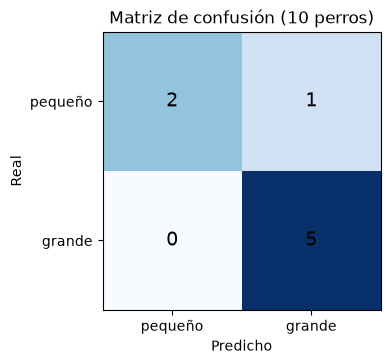

In [218]:
orden = ['pequeño', 'grande']
cm = pd.crosstab(por_perro['size'], por_perro['pred']).reindex(index=orden, columns=orden, fill_value=0)
print(cm)

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(cm.values, cmap='Blues')
ax.set_xticks([0, 1]); ax.set_xticklabels(orden)
ax.set_yticks([0, 1]); ax.set_yticklabels(orden)
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm.values[i, j], ha='center', va='center', fontsize=14)
ax.set_xlabel('Predicho'); ax.set_ylabel('Real')
ax.set_title('Matriz de confusión (10 perros)')
plt.tight_layout(); plt.show()

# Considerando cada raza disponible en DogsSpeakTDS como una categoría independiente.

In [219]:
razas = sorted(df['breed'].unique())
print(razas)

X_razas = X_tds[:, idx_sin_c0]               # 38 características, sin c0
raza_de_cada_audio = df['breed'].values

proto_raza = {}                               # raza -> vector prototipo
for raza in razas:
    audios_de_la_raza = X_razas[raza_de_cada_audio == raza]
    proto_raza[raza] = audios_de_la_raza.mean(axis=0)
    print(f'{raza:16s} {len(audios_de_la_raza):3d} audios')

['chihuahua', 'german shepherd', 'husky', 'pitbull', 'shiba inu']
chihuahua         48 audios
german shepherd   62 audios
husky             56 audios
pitbull           54 audios
shiba inu         48 audios


                  n   media     std  mediana     IQR
raza                                                
chihuahua        48  0.1609  0.1253   0.1220  0.1125
german shepherd  62  0.1394  0.1502   0.0765  0.0901
husky            56  0.1400  0.1145   0.1054  0.0876
pitbull          54  0.1386  0.1251   0.0891  0.1272
shiba inu        48  0.1614  0.1070   0.1401  0.1023


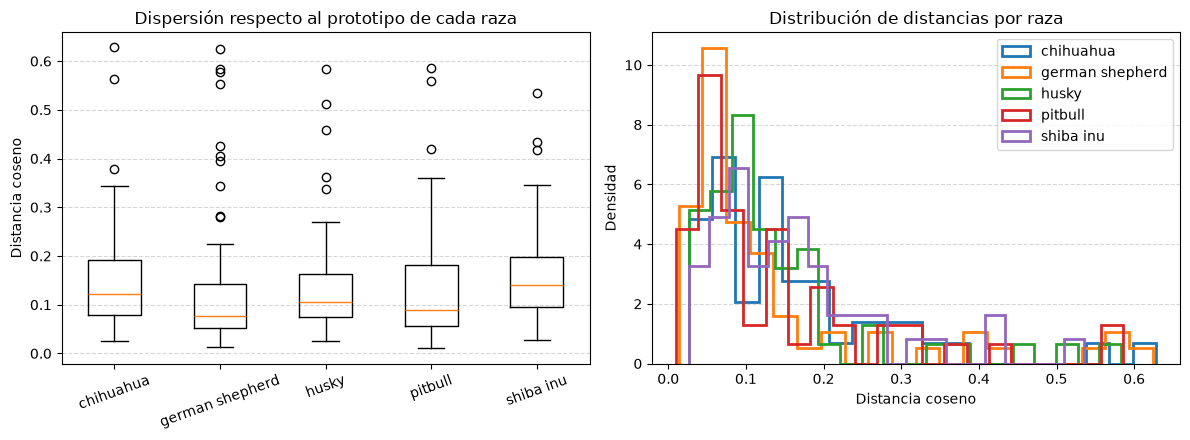

In [220]:
dist_raza = {}                                # raza -> distancias coseno de sus audios
for raza in razas:
    audios_de_la_raza = X_razas[raza_de_cada_audio == raza]
    dist_raza[raza] = np.array([cosine(x, proto_raza[raza]) for x in audios_de_la_raza])

filas = []
for raza in razas:
    d = dist_raza[raza]
    filas.append({'raza': raza, 'n': len(d), 'media': d.mean(), 'std': d.std(),
                  'mediana': np.median(d),
                  'IQR': np.percentile(d, 75) - np.percentile(d, 25)})

tabla_razas = pd.DataFrame(filas).set_index('raza').round(4)
print(tabla_razas)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Boxplot
axes[0].boxplot([dist_raza[r] for r in razas], tick_labels=razas)
axes[0].set_title('Dispersión respecto al prototipo de cada raza')
axes[0].set_ylabel('Distancia coseno')
axes[0].tick_params(axis='x', rotation=20)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Histogramas (solo el contorno, para que no se tapen)
for raza in razas:
    axes[1].hist(dist_raza[raza], bins=20, density=True, histtype='step', linewidth=2, label=raza)
axes[1].set_title('Distribución de distancias por raza')
axes[1].set_xlabel('Distancia coseno')
axes[1].set_ylabel('Densidad')
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Pruebas estadisticas

In [221]:
ALPHA = 0.05

# CUESTION DE NORMALIDAD: Shapiro-Wilk para cada raza
todas_normales = True
for raza in razas:
    _, p = stats.shapiro(dist_raza[raza])
    print(f'Shapiro {raza:16s}: p = {p:.3e}')
    if p < ALPHA:
        todas_normales = False

print('\nTodas normales:', todas_normales)

# Si todas las distribuciones son normales, se usa t de Welch; si no, Mann-Whitney
numero_de_pares = len(razas) * (len(razas) - 1) // 2     # 10
alfa_corregido = ALPHA / numero_de_pares                  # 0.005

resultados = []
for i in range(len(razas)):
    for j in range(i + 1, len(razas)):
        raza_1, raza_2 = razas[i], razas[j]

        if todas_normales:
            _, p = stats.ttest_ind(dist_raza[raza_1], dist_raza[raza_2], equal_var=False)
        else:
            _, p = stats.mannwhitneyu(dist_raza[raza_1], dist_raza[raza_2])

        mediana_1 = np.median(dist_raza[raza_1])
        mediana_2 = np.median(dist_raza[raza_2])
        mas_concentrada = raza_1 if mediana_1 < mediana_2 else raza_2

        resultados.append({'raza_1': raza_1, 'raza_2': raza_2, 'p': p,
                           'hay_diferencia': p < alfa_corregido,
                           'mas_concentrada': mas_concentrada})

prueba = 't de Welch' if todas_normales else 'Mann-Whitney'
print(f'Prueba: {prueba} | alfa corregido = {alfa_corregido}')
print(pd.DataFrame(resultados).round(5).to_string(index=False))
print('\n')

# CHI CUADRADO PARA COMPARAR RAZA Y CERCANIA AL PROTOTIPO
todas_las_distancias = np.concatenate([dist_raza[r] for r in razas])
umbral = np.median(todas_las_distancias)                  # "cerca" = por debajo de la mediana global

conteos = []
for raza in razas:
    cerca = (dist_raza[raza] <= umbral).sum()
    lejos = (dist_raza[raza] > umbral).sum()
    conteos.append([cerca, lejos])

tabla_chi = pd.DataFrame(conteos, index=razas, columns=['Cerca', 'Lejos'])
tabla_chi['% cerca'] = (tabla_chi['Cerca'] / (tabla_chi['Cerca'] + tabla_chi['Lejos']) * 100).round(1)
print(tabla_chi)

chi2, p_chi, gl, esperados = stats.chi2_contingency(tabla_chi[['Cerca', 'Lejos']])
print(f'\nchi2 = {chi2:.3f}, gl = {gl}, p = {p_chi:.6f}, esperado mínimo = {esperados.min():.1f}')
print('Se rechaza H0' if p_chi < ALPHA else 'No se rechaza H0')

Shapiro chihuahua       : p = 2.860e-06
Shapiro german shepherd : p = 6.738e-10
Shapiro husky           : p = 2.254e-08
Shapiro pitbull         : p = 2.081e-07
Shapiro shiba inu       : p = 7.630e-05

Todas normales: False
Prueba: Mann-Whitney | alfa corregido = 0.005
         raza_1          raza_2       p  hay_diferencia mas_concentrada
      chihuahua german shepherd 0.01952           False german shepherd
      chihuahua           husky 0.34276           False           husky
      chihuahua         pitbull 0.13403           False         pitbull
      chihuahua       shiba inu 0.63126           False       chihuahua
german shepherd           husky 0.09640           False german shepherd
german shepherd         pitbull 0.51190           False german shepherd
german shepherd       shiba inu 0.00583           False german shepherd
          husky         pitbull 0.48607           False         pitbull
          husky       shiba inu 0.09315           False           husky
        pit

In [222]:
matriz = pd.DataFrame(index=razas, columns=razas, dtype=float)

for raza_real in razas:
    audios = X_razas[raza_de_cada_audio == raza_real]
    for raza_proto in razas:
        distancias = [cosine(x, proto_raza[raza_proto]) for x in audios]
        matriz.loc[raza_real, raza_proto] = np.mean(distancias)

print('Filas: raza real del audio | Columnas: prototipo de comparación')
print(matriz.round(3))

Filas: raza real del audio | Columnas: prototipo de comparación
                 chihuahua  german shepherd  husky  pitbull  shiba inu
chihuahua            0.161            0.182  0.181    0.177      0.174
german shepherd      0.153            0.139  0.148    0.150      0.164
husky                0.159            0.152  0.140    0.158      0.155
pitbull              0.151            0.154  0.154    0.139      0.164
shiba inu            0.182            0.198  0.186    0.193      0.161


Contraste de distancia, porcentaje por audio y reparto por perro

In [223]:
distancias_mis = np.zeros((len(mis), len(razas)))

for i, x in enumerate(Xm):
    for k, raza in enumerate(razas):
        distancias_mis[i, k] = cosine(x, proto_raza[raza])

print(pd.DataFrame(distancias_mis, columns=razas).round(3).head())

EPSILON = 1e-9                                  # evita dividir entre cero si una distancia fuera 0

pesos = 1 / (distancias_mis + EPSILON)          # peso = inverso de la distancia
porcentajes = 100 * pesos / pesos.sum(axis=1, keepdims=True)

tabla_audio = pd.DataFrame(porcentajes, columns=razas)
tabla_audio.insert(0, 'dog_id', mis['dog_id'].values)

print(tabla_audio.round(1).head(6))
print('Suma por audio (primeros 5):', porcentajes.sum(axis=1)[:5].round(6))     # debe dar 100
print(f'Porcentaje mínimo = {porcentajes.min():.1f} | máximo = {porcentajes.max():.1f}')

porcentajes_perro = tabla_audio.groupby('dog_id')[razas].mean()

print(porcentajes_perro.round(1))
print('\nSuma por perro:', porcentajes_perro.sum(axis=1).round(6).tolist())
print('\nRaza más parecida:')
print(porcentajes_perro.idxmax(axis=1))

   chihuahua  german shepherd  husky  pitbull  shiba inu
0      0.077            0.035  0.054    0.067      0.111
1      0.090            0.046  0.060    0.072      0.116
2      0.080            0.037  0.047    0.075      0.100
3      0.074            0.054  0.052    0.094      0.091
4      0.069            0.032  0.046    0.070      0.086
   dog_id  chihuahua  german shepherd  husky  pitbull  shiba inu
0  Alaska       15.4             34.2   22.1     17.7       10.7
1  Alaska       15.4             30.0   23.2     19.3       12.0
2  Alaska       14.9             31.9   25.2     16.0       12.0
3   Aslan       18.5             25.5   26.4     14.6       15.1
4   Aslan       15.4             33.7   23.1     15.3       12.5
5   Aslan       16.8             32.4   22.8     14.1       14.0
Suma por audio (primeros 5): [100. 100. 100. 100. 100.]
Porcentaje mínimo = 10.7 | máximo = 34.2
           chihuahua  german shepherd  husky  pitbull  shiba inu
dog_id                                   

# FUNCIÓN COMPLETA

In [224]:
EPSILON = 1e-9    # evita dividir entre cero si una distancia fuera 0

def predecir_ladrido(ruta_audio):
    """
    Recibe la ruta de una grabación (cualquier frecuencia de muestreo) y devuelve
    el tamaño predicho y el porcentaje de similitud con cada raza de DogsSpeakTDS.
    """
    # Características: misma extracción de todo el trabajo (remuestrea a 16 kHz, ventana de 25 ms, solape 50%, 40 coeficientes MFCC, resumen temporal)
    x = extraer_mfcc_audio(ruta_audio)[idx_sin_c0]

    # Tamaño: gana el prototipo con menor distancia coseno
    d_grande = cosine(x, proto_grande)
    d_pequeno = cosine(x, proto_pequeno)
    tamano = 'grande' if d_grande < d_pequeno else 'pequeño'

    # Razas: distancia a cada prototipo y reparto inverso a la distancia
    distancias = np.array([cosine(x, proto_raza[raza]) for raza in razas])
    pesos = 1 / (distancias + EPSILON)
    porcentajes = 100 * pesos / pesos.sum()

    por_raza = dict(zip(razas, porcentajes))
    por_raza = dict(sorted(por_raza.items(), key=lambda par: par[1], reverse=True))

    # Data relevante a observar
    print(f'Audio: {ruta_audio}')
    print(f'Distancia al prototipo grande : {d_grande:.4f}')
    print(f'Distancia al prototipo pequeño: {d_pequeno:.4f}')
    print(f'Tamaño predicho: {tamano.upper()}')
    print('Similitud con las razas:')
    for raza, porcentaje in por_raza.items():
        print(f'  {raza:16s} {porcentaje:5.1f} %')

    return {'tamano': tamano, 'similitud_razas_%': por_raza}

resultado = predecir_ladrido(mis['ruta'].iloc[0])



Audio: MisPerros\Grandes\Alaska\alaska_ladrido_1.wav
Distancia al prototipo grande : 0.0463
Distancia al prototipo pequeño: 0.0945
Tamaño predicho: GRANDE
Similitud con las razas:
  german shepherd   34.2 %
  husky             22.1 %
  pitbull           17.7 %
  chihuahua         15.4 %
  shiba inu         10.7 %


# Gráficas de mayor análisis (Para informe)

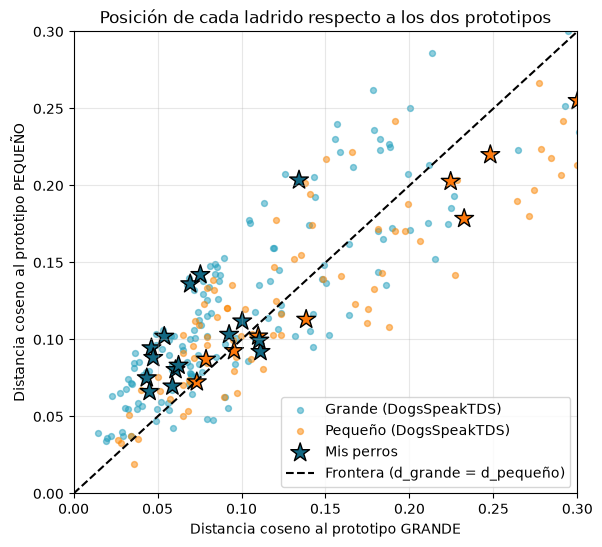

In [225]:
Xt = X_tds[:, idx_sin_c0]
d_g = np.array([cosine(x, proto_grande)  for x in Xt])
d_p = np.array([cosine(x, proto_pequeno) for x in Xt])
es_g = (df['size'] == 'grande').values

plt.figure(figsize=(6.5, 6))
plt.scatter(d_g[es_g],  d_p[es_g],  s=18, alpha=0.5, c='#219EBC', label='Grande (DogsSpeakTDS)')
plt.scatter(d_g[~es_g], d_p[~es_g], s=18, alpha=0.5, c='#FB8500', label='Pequeño (DogsSpeakTDS)')

# Tus perros (opcional)
col = mis['size'].map({'grande': "#126782", 'pequeño': "#FF790B"})
plt.scatter(mis['d_grande'], mis['d_pequeno'], marker='*', s=200, c=col, edgecolor='k', label='Mis perros')

lim = max(d_g.max(), d_p.max())
plt.plot([0, lim], [0, lim], 'k--', label='Frontera (d_grande = d_pequeño)')
plt.xlabel('Distancia coseno al prototipo GRANDE')
plt.ylabel('Distancia coseno al prototipo PEQUEÑO')
plt.xlim(0, 0.3); 
plt.ylim(0, 0.3)
plt.title('Posición de cada ladrido respecto a los dos prototipos')
plt.legend(); plt.grid(alpha=0.3); plt.show()